# Alibaba GPU Cluster Trace 2020 — Workload Analysis

Mục tiêu: Extract arrival rate và job duration distribution để calibrate WorkloadGenerator trong spot-rl.

**Files sử dụng:**
- `pai_job_table.csv` — job-level: start_time, end_time, status
- `pai_task_table.csv` — task-level: gpu_type, plan_gpu, plan_cpu, duration
- `pai_group_tag_table.csv` — workload tag (training / inference / ...)

**Time unit:** seconds (epoch của cluster, không phải Unix timestamp)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='darkgrid')
plt.rcParams['figure.dpi'] = 120

DATA_DIR = '../data/raw/alibaba_workload'
OUT_DIR  = '../data/processed/alibaba_workload'
os.makedirs(OUT_DIR, exist_ok=True)

print('Data dir:', os.path.abspath(DATA_DIR))

Data dir: d:\Document\Seminar_MLOps\spot-rl-optimiztion\data\raw\alibaba_workload


## 1. Load dữ liệu

In [2]:
print('Loading pai_job_table...')
jobs = pd.read_csv(f'{DATA_DIR}/pai_job_table.csv')
print(f'  jobs: {jobs.shape}')
print(jobs.dtypes)
jobs.head(3)

Loading pai_job_table...
  jobs: (1055501, 6)
job_name          str
inst_id           str
user              str
status            str
start_time    float64
end_time      float64
dtype: object


,job_name,inst_id,user,status,start_time,end_time
0,87a79c6373f7439d82f32a1c,38e2d7187762a9241cc1cd5732dbe52a5d8b37ed7dafe1...,74238accb90b,Running,1053513.0,NaN
1,9605ac7cc4c55a193fbe956b,e1cbdf28400847d65d00da4f0522ce7a43275fe9cb5d2a...,61d6b6dd5b15,Running,1097614.0,NaN
2,a2d8872d080eb634a42ea9a6,27ddabc2f7490279c6d5bd95c8a75e5c96d841c6030659...,61d6b6dd5b15,Running,1103820.0,NaN


In [3]:
print('Loading pai_task_table...')
tasks = pd.read_csv(f'{DATA_DIR}/pai_task_table.csv')
print(f'  tasks: {tasks.shape}')
tasks.head(3)

Loading pai_task_table...
  tasks: (1261050, 10)


,job_name,task_name,inst_num,status,start_time,end_time,plan_cpu,plan_mem,plan_gpu,gpu_type
0,c936346f45eccd34bf748541,tensorflow,1.0,Terminated,2693235.0,2695847.0,600.0,29.296875,50.0,MISC
1,455c3dec270f4777ad67721c,tensorflow,1.0,Terminated,3399583.0,3399732.0,600.0,29.296875,100.0,MISC
2,ba64aa2f0feff18428923e92,tensorflow,1.0,Terminated,2152271.0,2158213.0,600.0,29.296875,50.0,MISC


In [4]:
print('Loading pai_group_tag_table...')
tags = pd.read_csv(f'{DATA_DIR}/pai_group_tag_table.csv')
print(f'  tags: {tags.shape}')
print('Workload types:')
print(tags['workload'].value_counts())
tags.head(3)

Loading pai_group_tag_table...
  tags: (1055032, 5)
Workload types:
workload
bert          54887
ctr           27083
nmt           10363
inception      5440
graphlearn     3754
resnet          541
xlnet           415
rl              249
vgg              66
Name: count, dtype: int64


,inst_id,user,gpu_type_spec,group,workload
0,c1bdfdda2af739f74be81079cfe176800093c65907b3a9...,58540f191766,NaN,ba4e3be6472ded359f4b1ca53d9bd53e,NaN
1,a8c39faded8b9a5b7436a47aff747835795cec39ef33c7...,58540f191766,NaN,81b1eed4c4b0463b7e5a154f7c42db1e,NaN
2,26bf18df11f3a989fa64ed808dc780ab24a7700941f7c1...,58540f191766,NaN,046437ed700bdf7434aa88503cc97a8d,NaN


## 2. Clean & Filter Jobs

In [5]:
print('=== Job status distribution ===')
print(jobs['status'].value_counts())
print()

# Chỉ giữ job đã Terminated (completed) — có đủ start + end time
jobs_done = jobs[
    (jobs['status'] == 'Terminated') &
    (jobs['start_time'].notna()) &
    (jobs['end_time'].notna()) &
    (jobs['end_time'] > jobs['start_time'])
].copy()

# Duration tính bằng giây → chuyển sang phút
jobs_done['duration_sec'] = jobs_done['end_time'] - jobs_done['start_time']
jobs_done['duration_min'] = jobs_done['duration_sec'] / 60

print(f'Jobs completed (Terminated): {len(jobs_done):,}')
print(f'Time range: {jobs_done["start_time"].min():.0f} — {jobs_done["start_time"].max():.0f} seconds')
span_days = (jobs_done['start_time'].max() - jobs_done['start_time'].min()) / 86400
print(f'Dataset span: {span_days:.1f} days')

=== Job status distribution ===
status
Terminated    732355
Failed        256555
Running        62928
Waiting         3663
Name: count, dtype: int64

Jobs completed (Terminated): 732,355
Time range: 542323 — 6451081 seconds
Dataset span: 68.4 days


## 3. Job Duration Distribution

In [6]:
dur = jobs_done['duration_min']

print('=== Duration stats (minutes) ===')
print(f'  mean:   {dur.mean():.1f} min')
print(f'  median: {dur.median():.1f} min')
print(f'  p25:    {dur.quantile(0.25):.1f} min')
print(f'  p75:    {dur.quantile(0.75):.1f} min')
print(f'  p90:    {dur.quantile(0.90):.1f} min')
print(f'  p99:    {dur.quantile(0.99):.1f} min')
print(f'  max:    {dur.max():.1f} min')

# Phân loại job type theo duration
def classify_job(d):
    if d < 5:
        return 'short (<5min) — CI/CD-like'
    elif d < 60:
        return 'medium (5-60min)'
    else:
        return 'long (>60min) — ML training-like'

jobs_done['job_type'] = jobs_done['duration_min'].apply(classify_job)
print()
print('=== Job type distribution ===')
print(jobs_done['job_type'].value_counts())
print()
pct = jobs_done['job_type'].value_counts(normalize=True) * 100
print(pct.round(1))

=== Duration stats (minutes) ===
  mean:   89.7 min
  median: 11.1 min
  p25:    2.4 min
  p75:    64.5 min
  p90:    214.1 min
  p99:    1148.1 min
  max:    10439.7 min

=== Job type distribution ===
job_type
short (<5min) — CI/CD-like          272910
medium (5-60min)                    267955
long (>60min) — ML training-like    191490
Name: count, dtype: int64

job_type
short (<5min) — CI/CD-like          37.3
medium (5-60min)                    36.6
long (>60min) — ML training-like    26.1
Name: proportion, dtype: float64


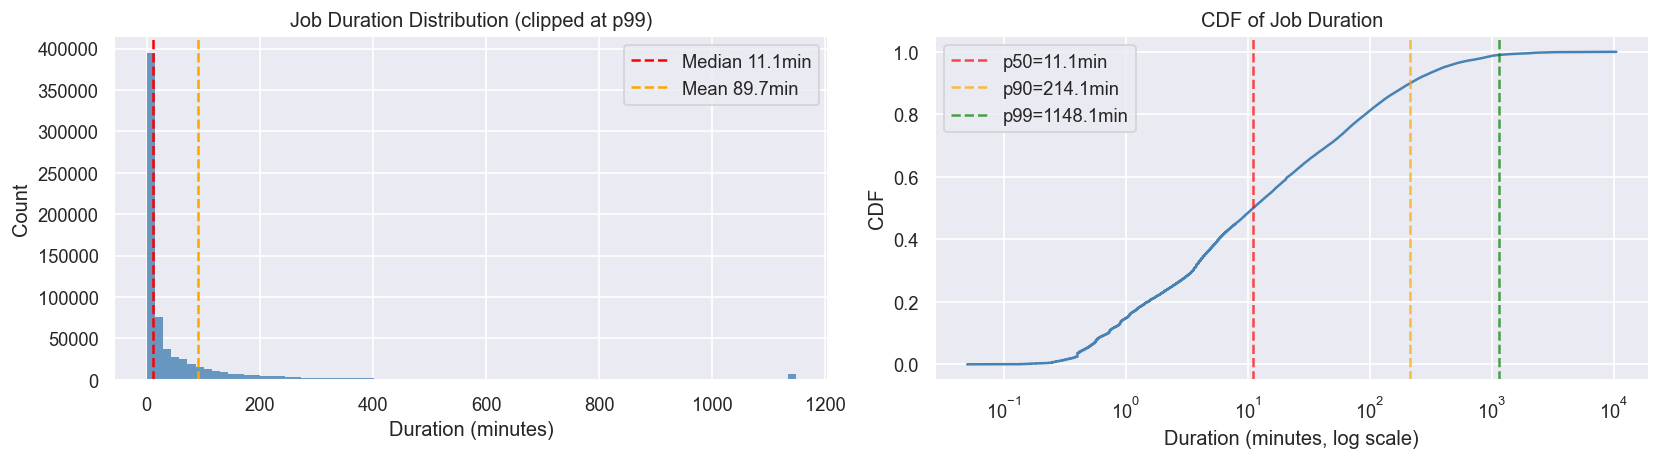

Saved duration_distribution.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Log-scale histogram
ax = axes[0]
ax.hist(dur.clip(upper=dur.quantile(0.99)), bins=80, color='steelblue', edgecolor='none', alpha=0.8)
ax.set_xlabel('Duration (minutes)')
ax.set_ylabel('Count')
ax.set_title('Job Duration Distribution (clipped at p99)')
ax.axvline(dur.median(), color='red', linestyle='--', label=f'Median {dur.median():.1f}min')
ax.axvline(dur.mean(), color='orange', linestyle='--', label=f'Mean {dur.mean():.1f}min')
ax.legend()

# CDF
ax2 = axes[1]
sorted_dur = np.sort(dur)
cdf = np.arange(1, len(sorted_dur)+1) / len(sorted_dur)
ax2.plot(sorted_dur, cdf, color='steelblue')
ax2.set_xscale('log')
ax2.set_xlabel('Duration (minutes, log scale)')
ax2.set_ylabel('CDF')
ax2.set_title('CDF of Job Duration')
for pct_val, color in [(0.5,'red'), (0.9,'orange'), (0.99,'green')]:
    val = dur.quantile(pct_val)
    ax2.axvline(val, color=color, linestyle='--', alpha=0.7, label=f'p{int(pct_val*100)}={val:.1f}min')
ax2.legend()

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/duration_distribution.png', dpi=150)
plt.show()
print('Saved duration_distribution.png')

## 4. Arrival Rate theo 15-phút slot

In [8]:
SLOT_SEC = 15 * 60  # 15 phút = 900 giây

t_min = jobs_done['start_time'].min()
jobs_done['slot'] = ((jobs_done['start_time'] - t_min) / SLOT_SEC).astype(int)

# Arrival rate toàn bộ
arrival_all = jobs_done.groupby('slot').size().rename('jobs_per_slot')

# Arrival rate theo job type
arrival_by_type = jobs_done.groupby(['slot', 'job_type']).size().unstack(fill_value=0)

print('=== Arrival rate (jobs/15min) ===')
print(f'  mean:   {arrival_all.mean():.2f}')
print(f'  median: {arrival_all.median():.2f}')
print(f'  p25:    {arrival_all.quantile(0.25):.2f}')
print(f'  p75:    {arrival_all.quantile(0.75):.2f}')
print(f'  p95:    {arrival_all.quantile(0.95):.2f}')
print(f'  max:    {arrival_all.max():.0f}')
print(f'  Total slots: {len(arrival_all)}')

=== Arrival rate (jobs/15min) ===
  mean:   120.89
  median: 106.00
  p25:    75.00
  p75:    149.00
  p95:    249.15
  max:    1466
  Total slots: 6058


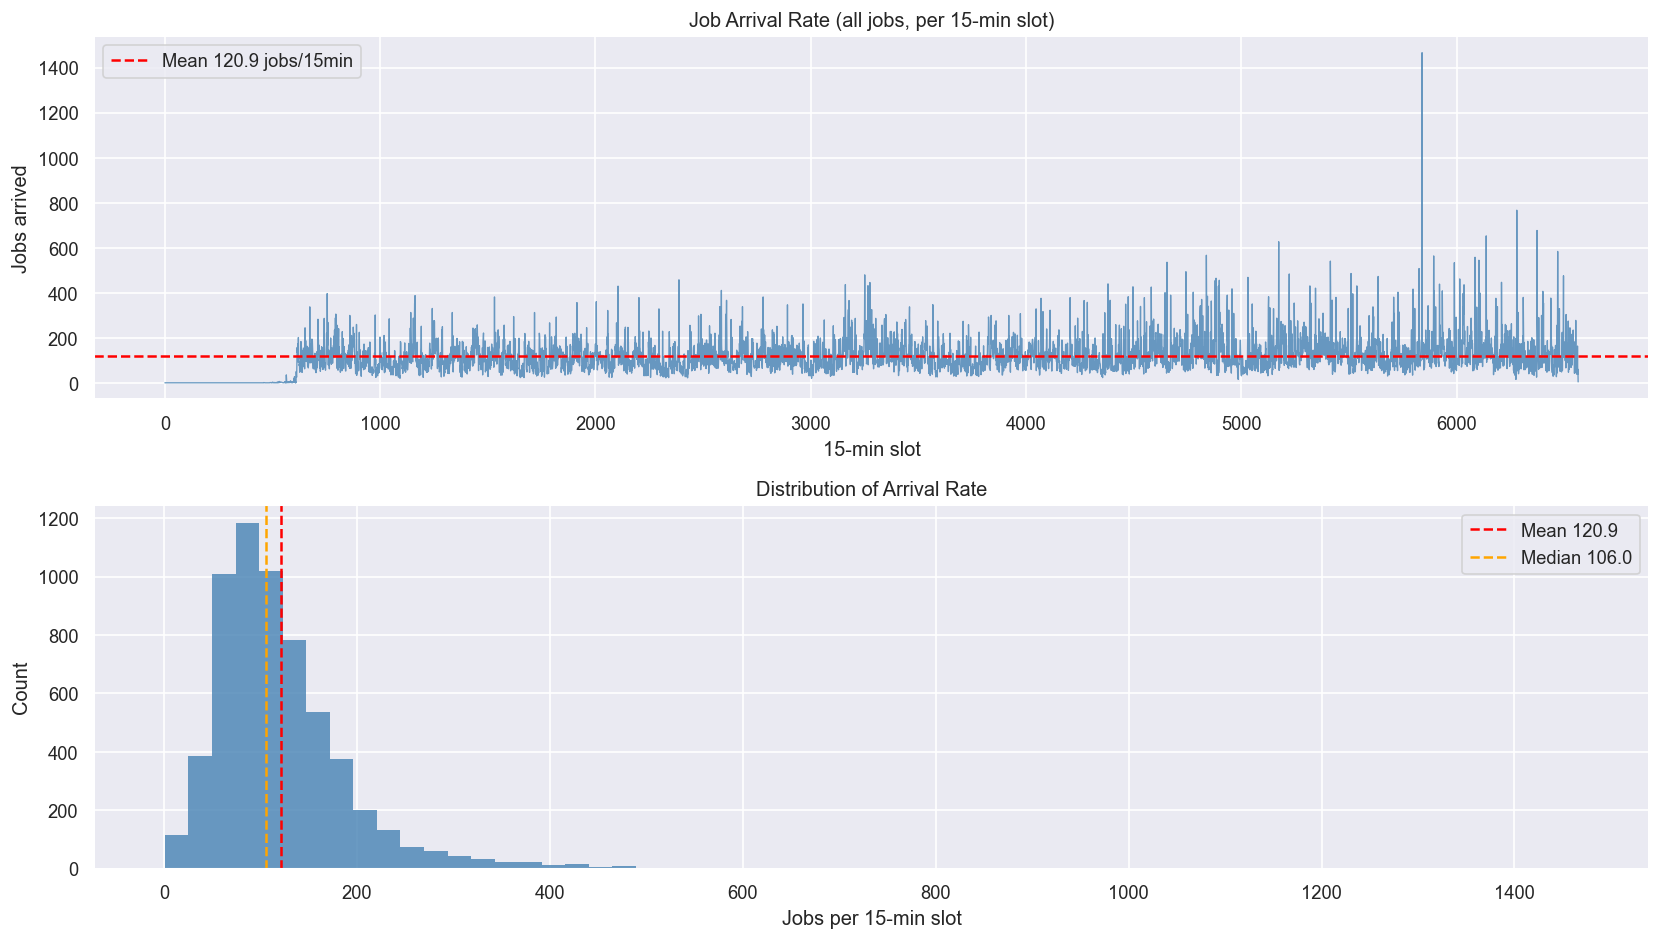

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Time series arrival rate
ax = axes[0]
ax.plot(arrival_all.index, arrival_all.values, linewidth=0.8, color='steelblue', alpha=0.8)
ax.axhline(arrival_all.mean(), color='red', linestyle='--', label=f'Mean {arrival_all.mean():.1f} jobs/15min')
ax.set_xlabel('15-min slot')
ax.set_ylabel('Jobs arrived')
ax.set_title('Job Arrival Rate (all jobs, per 15-min slot)')
ax.legend()

# Histogram arrival rate
ax2 = axes[1]
ax2.hist(arrival_all.values, bins=60, color='steelblue', edgecolor='none', alpha=0.8)
ax2.axvline(arrival_all.mean(), color='red', linestyle='--', label=f'Mean {arrival_all.mean():.1f}')
ax2.axvline(arrival_all.median(), color='orange', linestyle='--', label=f'Median {arrival_all.median():.1f}')
ax2.set_xlabel('Jobs per 15-min slot')
ax2.set_ylabel('Count')
ax2.set_title('Distribution of Arrival Rate')
ax2.legend()

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/arrival_rate.png', dpi=150)
plt.show()

## 5. Phân tích theo Job Type (ML training vs CI/CD)

In [10]:
# Duration stats theo từng job type
for jtype, grp in jobs_done.groupby('job_type'):
    d = grp['duration_min']
    n = len(grp)
    print(f'\n=== {jtype} (n={n:,}) ===')
    print(f'  mean={d.mean():.1f}min  median={d.median():.1f}min  p90={d.quantile(0.9):.1f}min')


=== long (>60min) — ML training-like (n=191,490) ===
  mean=311.0min  median=158.9min  p90=681.0min

=== medium (5-60min) (n=267,955) ===
  mean=21.0min  median=16.1min  p90=45.8min

=== short (<5min) — CI/CD-like (n=272,910) ===
  mean=1.9min  median=1.3min  p90=4.1min


In [11]:
# Arrival rate per job type
print('=== Arrival rate per 15min by job type ===')
for col in arrival_by_type.columns:
    s = arrival_by_type[col]
    print(f'\n{col}:')
    print(f'  mean={s.mean():.2f}  median={s.median():.2f}  p95={s.quantile(0.95):.2f}')

=== Arrival rate per 15min by job type ===

long (>60min) — ML training-like:
  mean=31.61  median=23.00  p95=83.00

medium (5-60min):
  mean=44.23  median=35.00  p95=102.00

short (<5min) — CI/CD-like:
  mean=45.05  median=34.00  p95=106.00


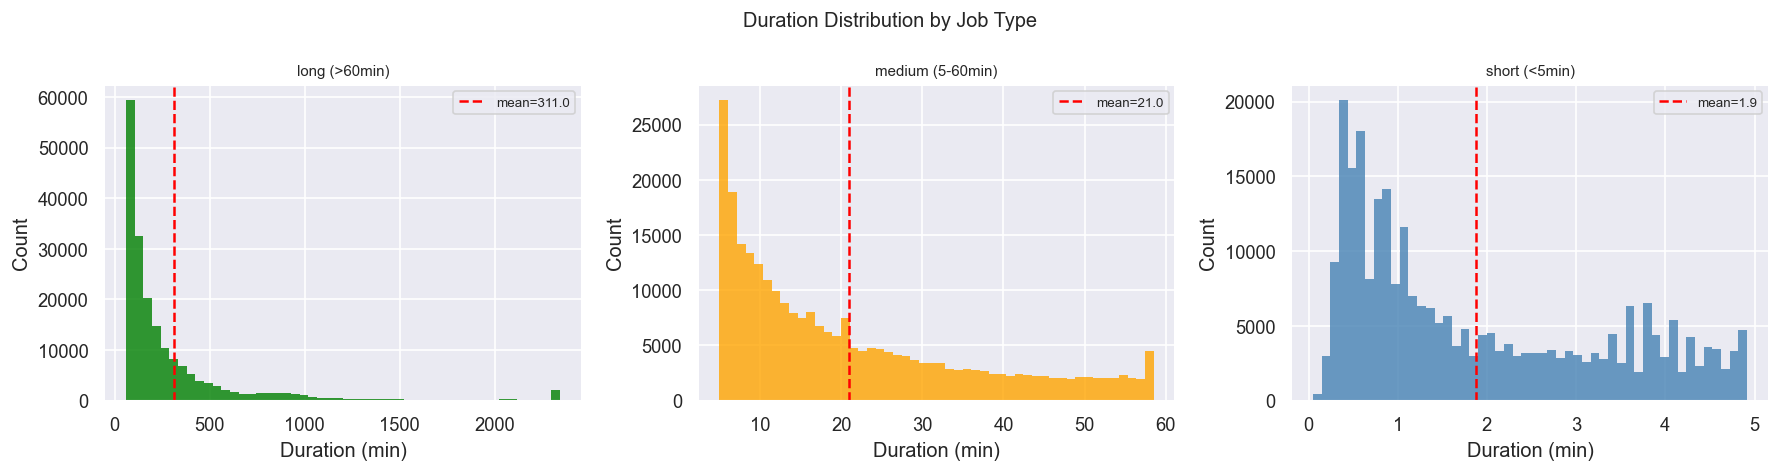

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = {'short (<5min) — CI/CD-like': 'steelblue',
          'medium (5-60min)': 'orange',
          'long (>60min) — ML training-like': 'green'}

for ax, (jtype, grp) in zip(axes, jobs_done.groupby('job_type')):
    d = grp['duration_min'].clip(upper=grp['duration_min'].quantile(0.99))
    color = colors.get(jtype, 'gray')
    ax.hist(d, bins=50, color=color, edgecolor='none', alpha=0.8)
    ax.set_title(jtype.split('—')[0].strip(), fontsize=9)
    ax.set_xlabel('Duration (min)')
    ax.set_ylabel('Count')
    ax.axvline(grp['duration_min'].mean(), color='red', linestyle='--',
               label=f'mean={grp["duration_min"].mean():.1f}')
    ax.legend(fontsize=8)

plt.suptitle('Duration Distribution by Job Type', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/duration_by_type.png', dpi=150)
plt.show()

## 6. Daily Pattern (Hour of Day)

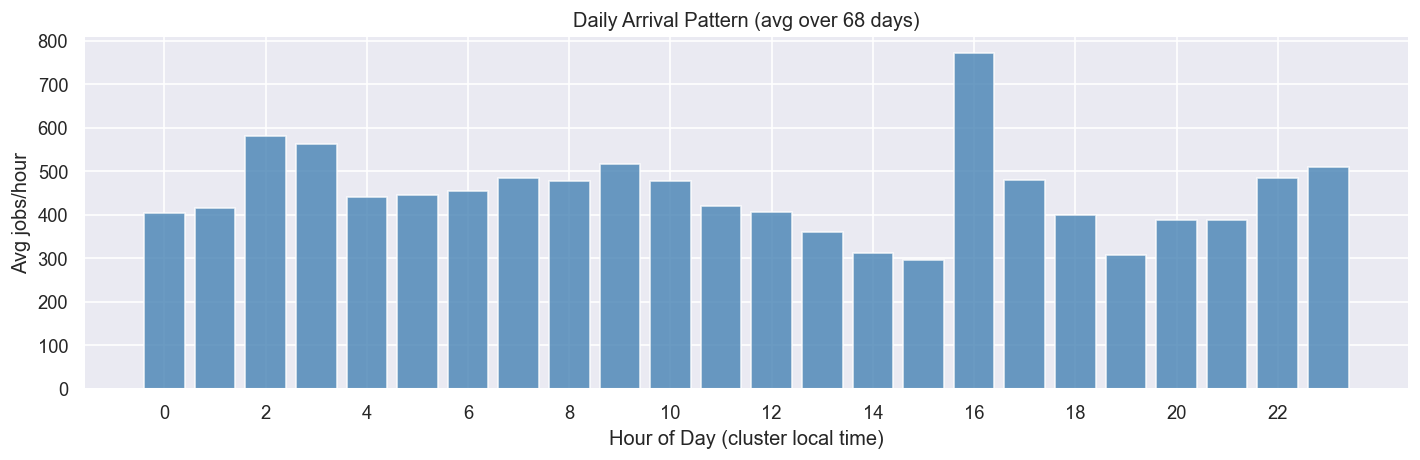

Peak hour: 16h (771.4 jobs/h)
Base hour: 15h (296.0 jobs/h)
Peak multiplier: 1.72x


In [13]:
# Convert cluster time → giờ trong ngày
# Cluster time là relative seconds từ epoch cluster
jobs_done['hour_of_day'] = ((jobs_done['start_time'] % 86400) / 3600).astype(int)
jobs_done['day'] = (jobs_done['start_time'] // 86400).astype(int)

hourly = jobs_done.groupby('hour_of_day').size()
# Normalize theo số ngày
n_days = jobs_done['day'].nunique()
hourly_avg = hourly / n_days

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(hourly_avg.index, hourly_avg.values, color='steelblue', alpha=0.8)
ax.set_xlabel('Hour of Day (cluster local time)')
ax.set_ylabel('Avg jobs/hour')
ax.set_title(f'Daily Arrival Pattern (avg over {n_days} days)')
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/daily_pattern.png', dpi=150)
plt.show()

peak_hour = hourly_avg.idxmax()
base_hour = hourly_avg.idxmin()
peak_multiplier = hourly_avg.max() / hourly_avg.mean()
print(f'Peak hour: {peak_hour}h ({hourly_avg.max():.1f} jobs/h)')
print(f'Base hour: {base_hour}h ({hourly_avg.min():.1f} jobs/h)')
print(f'Peak multiplier: {peak_multiplier:.2f}x')

## 7. GPU Resource Usage

In [14]:
# Merge với task table để lấy GPU info
task_gpu = tasks[tasks['status'] == 'Terminated'][['job_name', 'plan_gpu', 'plan_cpu', 'plan_mem', 'gpu_type']].copy()
task_gpu = task_gpu.groupby('job_name').agg({
    'plan_gpu': 'sum',
    'plan_cpu': 'sum',
    'plan_mem': 'sum',
    'gpu_type': 'first'
}).reset_index()

jobs_gpu = jobs_done.merge(task_gpu, on='job_name', how='left')

print('=== GPU request distribution ===')
print(jobs_gpu['plan_gpu'].value_counts().head(10))
print()
print('=== GPU type distribution ===')
print(jobs_gpu['gpu_type'].value_counts().head(10))

=== GPU request distribution ===
plan_gpu
100.0    324328
25.0     137638
50.0     126509
10.0      75288
0.0       17452
200.0     14968
5.0       13484
20.0      10979
500.0      3083
15.0       2774
Name: count, dtype: int64

=== GPU type distribution ===
gpu_type
MISC       456430
T4         183386
P100        49388
V100        16657
V100M32      9042
Name: count, dtype: int64


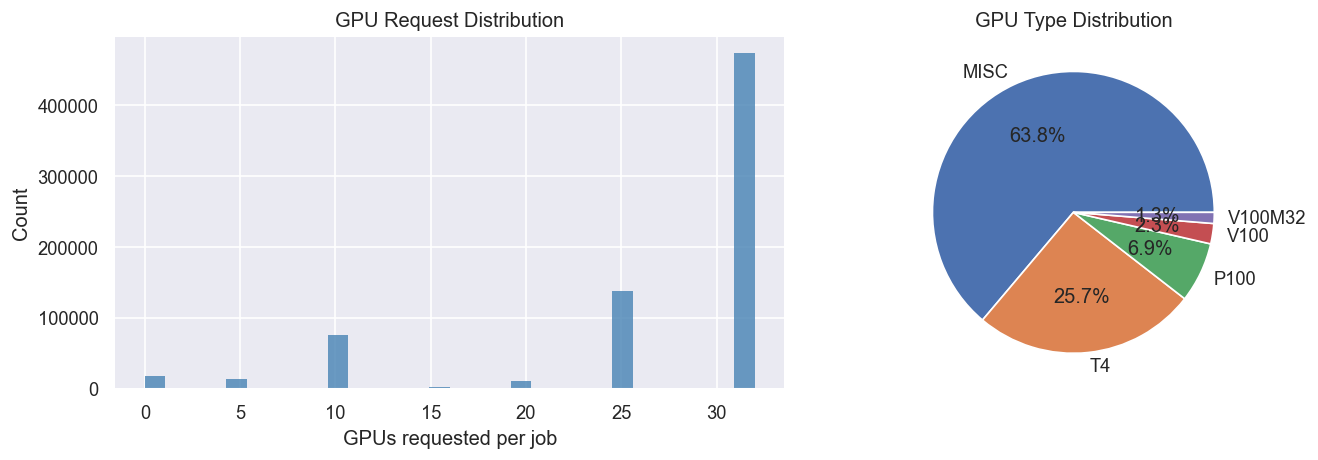

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# GPU count distribution
gpu_counts = jobs_gpu['plan_gpu'].dropna().clip(upper=32)
axes[0].hist(gpu_counts, bins=30, color='steelblue', edgecolor='none', alpha=0.8)
axes[0].set_xlabel('GPUs requested per job')
axes[0].set_ylabel('Count')
axes[0].set_title('GPU Request Distribution')

# GPU type pie
gpu_type_counts = jobs_gpu['gpu_type'].value_counts().head(6)
axes[1].pie(gpu_type_counts.values, labels=gpu_type_counts.index, autopct='%1.1f%%')
axes[1].set_title('GPU Type Distribution')

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/gpu_usage.png', dpi=150)
plt.show()

## 8. Summary — WorkloadGenerator Parameters

In [16]:
# === Tính parameters cho WorkloadGenerator ===

# Short jobs (CI/CD-like)
short = jobs_done[jobs_done['job_type'] == 'short (<5min) — CI/CD-like']['duration_min']
# Long jobs (ML training-like)
long_  = jobs_done[jobs_done['job_type'] == 'long (>60min) — ML training-like']['duration_min']

# Arrival rate per 15min
arr_short = jobs_done[jobs_done['job_type'] == 'short (<5min) — CI/CD-like'].groupby('slot').size()
arr_long  = jobs_done[jobs_done['job_type'] == 'long (>60min) — ML training-like'].groupby('slot').size()

print('=' * 55)
print('  WORKLOAD GENERATOR PARAMETERS (from Alibaba GPU 2020)')
print('=' * 55)
print()
print('--- CI/CD-like workload (short jobs) ---')
print(f'  base_arrival_rate : {arr_short.mean():.2f} jobs/15min')
print(f'  avg_job_duration  : {short.median():.1f} min (median)')
print(f'  peak_multiplier   : {peak_multiplier:.2f}x')
print()
print('--- ML Training workload (long jobs) ---')
if len(long_) > 0:
    print(f'  base_arrival_rate : {arr_long.mean():.2f} jobs/15min')
    print(f'  avg_job_duration  : {long_.median():.1f} min (median)')
    print(f'  peak_multiplier   : {peak_multiplier:.2f}x')
else:
    print('  (no long jobs in sample)')
print()
print('--- Combined workload ---')
print(f'  base_arrival_rate : {arrival_all.mean():.2f} jobs/15min')
print(f'  avg_job_duration  : {jobs_done["duration_min"].median():.1f} min (median)')
print(f'  peak_multiplier   : {peak_multiplier:.2f}x')
print('=' * 55)

  WORKLOAD GENERATOR PARAMETERS (from Alibaba GPU 2020)

--- CI/CD-like workload (short jobs) ---
  base_arrival_rate : 45.84 jobs/15min
  avg_job_duration  : 1.3 min (median)
  peak_multiplier   : 1.72x

--- ML Training workload (long jobs) ---
  base_arrival_rate : 31.64 jobs/15min
  avg_job_duration  : 158.9 min (median)
  peak_multiplier   : 1.72x

--- Combined workload ---
  base_arrival_rate : 120.89 jobs/15min
  avg_job_duration  : 11.1 min (median)
  peak_multiplier   : 1.72x


In [17]:
# Lưu processed data để dùng trong evaluate
summary = {
    'total_jobs': len(jobs_done),
    'span_days': span_days,
    'n_days': n_days,
    # CI/CD
    'cicd_arrival_rate_per_15min': float(arr_short.mean()) if len(arr_short) > 0 else 0,
    'cicd_duration_median_min': float(short.median()) if len(short) > 0 else 0,
    # ML training
    'ml_arrival_rate_per_15min': float(arr_long.mean()) if len(arr_long) > 0 else 0,
    'ml_duration_median_min': float(long_.median()) if len(long_) > 0 else 0,
    # Combined
    'combined_arrival_rate_per_15min': float(arrival_all.mean()),
    'combined_duration_median_min': float(jobs_done['duration_min'].median()),
    'peak_multiplier': float(peak_multiplier),
}

import json
with open(f'{OUT_DIR}/workload_params.json', 'w') as f:
    json.dump(summary, f, indent=2)

print('Saved workload_params.json')
print(json.dumps(summary, indent=2))

Saved workload_params.json
{
  "total_jobs": 732355,
  "span_days": 68.38840277777778,
  "n_days": 68,
  "cicd_arrival_rate_per_15min": 45.84411221232992,
  "cicd_duration_median_min": 1.3333333333333333,
  "ml_arrival_rate_per_15min": 31.640779907468605,
  "ml_duration_median_min": 158.93333333333334,
  "combined_arrival_rate_per_15min": 120.89055793991416,
  "combined_duration_median_min": 11.05,
  "peak_multiplier": 1.7190023963788055
}


## 9. Spike Pattern Analysis

In [18]:
# Detect spike slots (> mean + 2*std)
mean_arr = arrival_all.mean()
std_arr  = arrival_all.std()
spike_threshold = mean_arr + 2 * std_arr

spikes = arrival_all[arrival_all > spike_threshold]
spike_prob = len(spikes) / len(arrival_all)
spike_multiplier = (spikes.mean() / mean_arr) if len(spikes) > 0 else 1.0

print('=== Spike Analysis ===')
print(f'  spike_threshold   : {spike_threshold:.1f} jobs/15min (mean + 2σ)')
print(f'  spike_slots       : {len(spikes)} / {len(arrival_all)}')
print(f'  spike_probability : {spike_prob:.4f} ({spike_prob*100:.2f}%)')
print(f'  spike_multiplier  : {spike_multiplier:.2f}x')
print()
print('→ Dùng cho WorkloadGenerator:')
print(f'  spike_probability = {spike_prob:.3f}')
print(f'  spike_multiplier  = {spike_multiplier:.1f}')

=== Spike Analysis ===
  spike_threshold   : 266.8 jobs/15min (mean + 2σ)
  spike_slots       : 244 / 6058
  spike_probability : 0.0403 (4.03%)
  spike_multiplier  : 2.95x

→ Dùng cho WorkloadGenerator:
  spike_probability = 0.040
  spike_multiplier  = 2.9
